In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/shopify_stock.csv")

                       date   open   high    low  close  adj_close     volume  \
0 2015-05-21 04:00:00+00:00  2.800  2.874  2.411  2.568      2.568  123039000   
1 2015-05-22 04:00:00+00:00  2.607  3.110  2.600  2.831      2.831   28412000   
2 2015-05-26 04:00:00+00:00  2.980  3.034  2.908  2.965      2.965    8202000   
3 2015-05-27 04:00:00+00:00  3.067  3.081  2.700  2.750      2.750    7976000   
4 2015-05-28 04:00:00+00:00  2.755  2.774  2.648  2.745      2.745    4000000   

   Daily_Delta  Daily_Return  
0       -0.232     -8.285710  
1        0.224      8.592250  
2       -0.015     -0.503359  
3       -0.317    -10.335830  
4       -0.010     -0.362985  


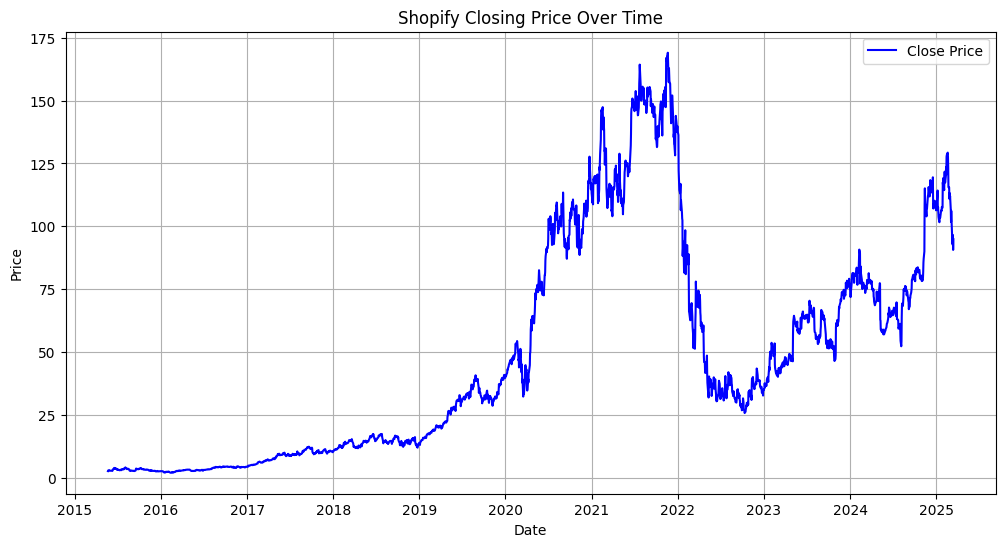

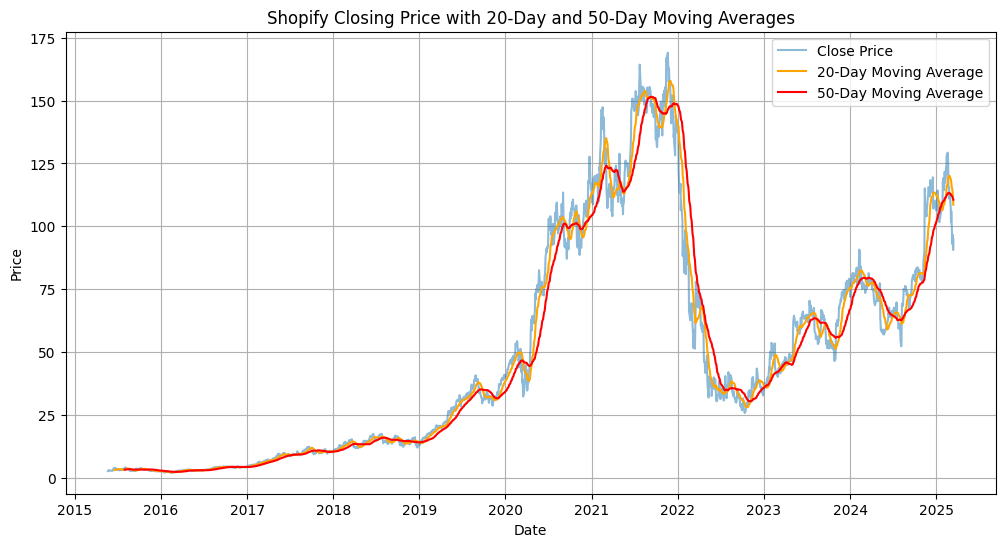

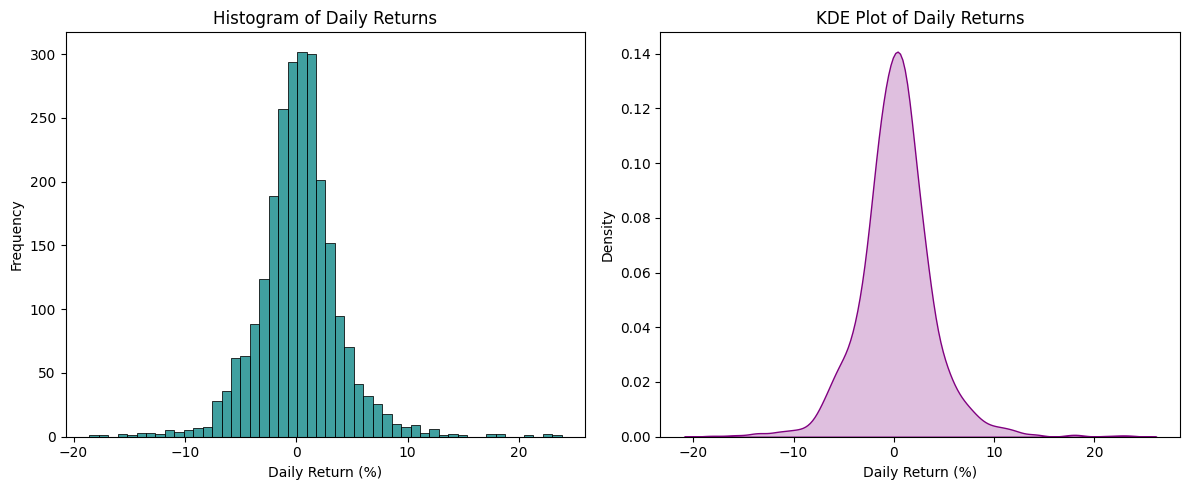

In [32]:
df["date"] = pd.to_datetime(df["date"], utc=True)
df = df.sort_values("date")
print(df.head())

plt.figure(figsize=(12, 6))
plt.plot(df["date"], df["close"], label="Close Price", color="blue")
plt.title("Shopify Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()


df["MA20"] = df["close"].rolling(window=20).mean()
df["MA50"] = df["close"].rolling(window=50).mean()

plt.figure(figsize=(12, 6))
plt.plot(df["date"], df["close"], label="Close Price", alpha=0.5)
plt.plot(df["date"], df["MA20"], label="20-Day Moving Average", color="orange")
plt.plot(df["date"], df["MA50"], label="50-Day Moving Average", color="red")
plt.title("Shopify Closing Price with 20-Day and 50-Day Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()


df["Daily_Return"] = df["close"].pct_change() * 100

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["Daily_Return"].dropna(), bins=50, color="teal", kde=False)
plt.title("Histogram of Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
sns.kdeplot(df["Daily_Return"].dropna(), color="purple", fill=True)
plt.title("KDE Plot of Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()